# DSC8307: Data Mining, Modelling and Analytics
## Project 1 – Wholesale Customer Segmentation

**Course:** DSC8307 — Data Mining, Modeling and Analytics  
**Programme:** Master of Science in Data Science and Analytics  
**Institution:** Uganda Christian University  
**Registration Number:** S25M19/013  
**Access Number:** B34983   
**Project:** Segment wholesale customers by spending behaviour and recommend differentiated service strategies.

---

### Executive summary

This study investigates annual expenditure patterns across 440 wholesale customers to identify distinct, actionable behavioral segments. The analysis focuses exclusively on six continuous monetary variables: Fresh, Milk, Grocery, Frozen, Detergents_Paper, and Delicatessen. To ensure the resulting segments reflect pure purchasing behavior rather than pre-existing administrative classifications, the categorical descriptors (Channel and Region) are withheld from the clustering phase and reserved strictly for post-hoc demographic profiling.  
Preliminary data validation confirmed a complete dataset of 440 unique records with zero missing values, duplicate entries, or negative expenditures. However, exploratory diagnostics revealed pronounced right-skewness across all six spending categories, with maximum expenditure values substantially exceeding their respective medians. Because extreme outliers and scale disparities can distort distance calculations, rigorous preprocessing is applied prior to modeling.  
To establish a robust segmentation framework, the study first evaluates the dataset's intrinsic cluster tendency before systematically comparing partitioning, hierarchical, and density-based clustering algorithms. Optimal model selection is governed by internal validation metrics, algorithmic stability, and commercial interpretability—ultimately translating mathematical clusters into targeted strategies for assortment planning, promotional targeting, delivery logistics, and account management.


## 1. Problem formulation and analytical plan

The primary analytical objective of this study is to uncover latent customer segments within wholesale distribution data based on their annual expenditure patterns across different product categories. Since the dataset does not contain predefined customer segment labels, the study treats customer segmentation as an unsupervised learning problem.

### Research questions

1. Are the spending observations sufficiently structured to justify clustering?
2. How do K-Means (partitioning), agglomerative hierarchical clustering and DBSCAN (density-based clustering) compare?
3. What spending behaviours characterise the resulting groups, and how should the distributor respond?

### Methodological decisions

- Cluster on `Fresh`, `Milk`, `Grocery`, `Frozen`, `Detergents_Paper` and `Delicatessen`.
- Exclude `Channel` and `Region` from distance calculations because they are coded customer descriptors, not spending amounts. Use them later to describe segments.
- Inspect skewness and extreme values. Wholesale spending is expected to be right-skewed; `log1p` transformation reduces the influence of very large values while retaining zero values.
- Standardise transformed variables so that categories measured on larger numeric scales do not dominate Euclidean distance.
- Compare K-Means, Ward agglomerative clustering and DBSCAN using silhouette, Davies–Bouldin and Calinski–Harabasz scores where their assumptions permit.
- Treat DBSCAN noise points explicitly. Its silhouette is calculated only on assigned observations and is reported alongside the proportion assigned.

In [3]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import (
    silhouette_score, davies_bouldin_score, calinski_harabasz_score
)
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA

RANDOM_STATE = 42
DATA_PATH = Path("wholesale-customers.csv")


df = pd.read_csv(DATA_PATH)
print(f"Dataset loaded: {df.shape[0]} rows × {df.shape[1]} columns")
display(df.head())

Dataset loaded: 440 rows × 8 columns


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


## 2. Data understanding and exploratory analysis

The assignment describes 440 wholesale customers and annual spending in monetary units. The available file contains eight columns: two customer descriptors (`Channel`, `Region`) and six annual spending categories.

The next cells inspect dimensions, data types, missing values, duplicates, descriptive statistics and distribution shape. This establishes whether cleaning or transformation is necessary rather than applying preparation steps without evidence.

In [4]:
print("Shape:", df.shape)
print("\nColumn names:", df.columns.tolist())
print("\nData types:")
display(df.dtypes.to_frame("data_type"))

print("\nMissing values:")
display(df.isna().sum().to_frame("missing_count"))

print("\nDuplicate rows:", int(df.duplicated().sum()))

print("\nDescriptive statistics:")
display(df.describe().T.round(2))

Shape: (440, 8)

Column names: ['Channel', 'Region', 'Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicatessen']

Data types:


,data_type
Channel,int64
Region,int64
Fresh,int64
Milk,int64
Grocery,int64
Frozen,int64
Detergents_Paper,int64
Delicatessen,int64



Missing values:


,missing_count
Channel,0
Region,0
Fresh,0
Milk,0
Grocery,0
Frozen,0
Detergents_Paper,0
Delicatessen,0



Duplicate rows: 0

Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
Channel,440.0,1.32,0.47,1.0,1.00,1.0,2.00,2.0
Region,440.0,2.54,0.77,1.0,2.00,3.0,3.00,3.0
Fresh,440.0,12000.30,12647.33,3.0,3127.75,8504.0,16933.75,112151.0
Milk,440.0,5796.27,7380.38,55.0,1533.00,3627.0,7190.25,73498.0
Grocery,440.0,7951.28,9503.16,3.0,2153.00,4755.5,10655.75,92780.0
Frozen,440.0,3071.93,4854.67,25.0,742.25,1526.0,3554.25,60869.0
Detergents_Paper,440.0,2881.49,4767.85,3.0,256.75,816.5,3922.00,40827.0
Delicatessen,440.0,1524.87,2820.11,3.0,408.25,965.5,1820.25,47943.0


In [5]:
spend_cols = [
    "Fresh", "Milk", "Grocery", "Frozen",
    "Detergents_Paper", "Delicatessen"
]
descriptor_cols = ["Channel", "Region"]

required_cols = spend_cols + descriptor_cols
missing_columns = sorted(set(required_cols) - set(df.columns))
if missing_columns:
    raise ValueError(f"Expected columns are missing: {missing_columns}")

# Check that spending variables are numeric and non-negative.
display(df[spend_cols].agg(["min", "median", "mean", "max", "std"]).T.round(2))
print("Negative spending values:", int((df[spend_cols] < 0).sum().sum()))

,min,median,mean,max,std
Fresh,3.0,8504.0,12000.30,112151.0,12647.33
Milk,55.0,3627.0,5796.27,73498.0,7380.38
Grocery,3.0,4755.5,7951.28,92780.0,9503.16
Frozen,25.0,1526.0,3071.93,60869.0,4854.67
Detergents_Paper,3.0,816.5,2881.49,40827.0,4767.85
Delicatessen,3.0,965.5,1524.87,47943.0,2820.11


Negative spending values: 0


### 2.1 Distribution, skewness and extreme observations

Spending variables often have long right tails: a small number of customers may spend substantially more than most customers. Means can therefore be pulled upward by a few large accounts. Histograms, boxplots and skewness statistics are used to assess this.

An extreme value is not automatically an error. In wholesale data, a very large account may be commercially genuine. Such values are investigated and retained unless there is evidence of invalid data.

,skewness,zero_count,unique_values
Delicatessen,11.152,0,403
Frozen,5.908,0,426
Milk,4.054,0,421
Detergents_Paper,3.632,0,417
Grocery,3.587,0,430
Fresh,2.561,0,433


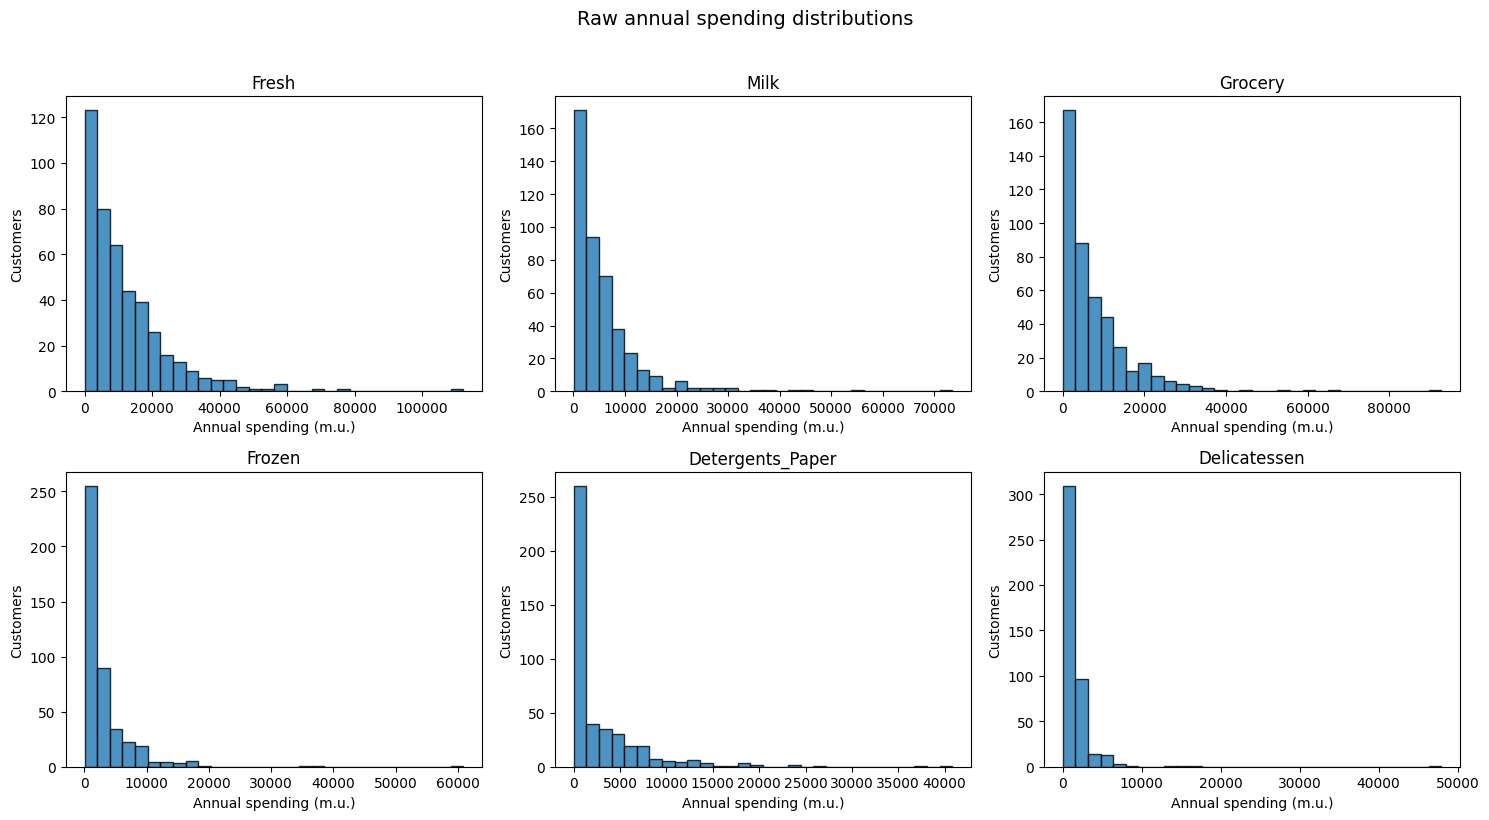

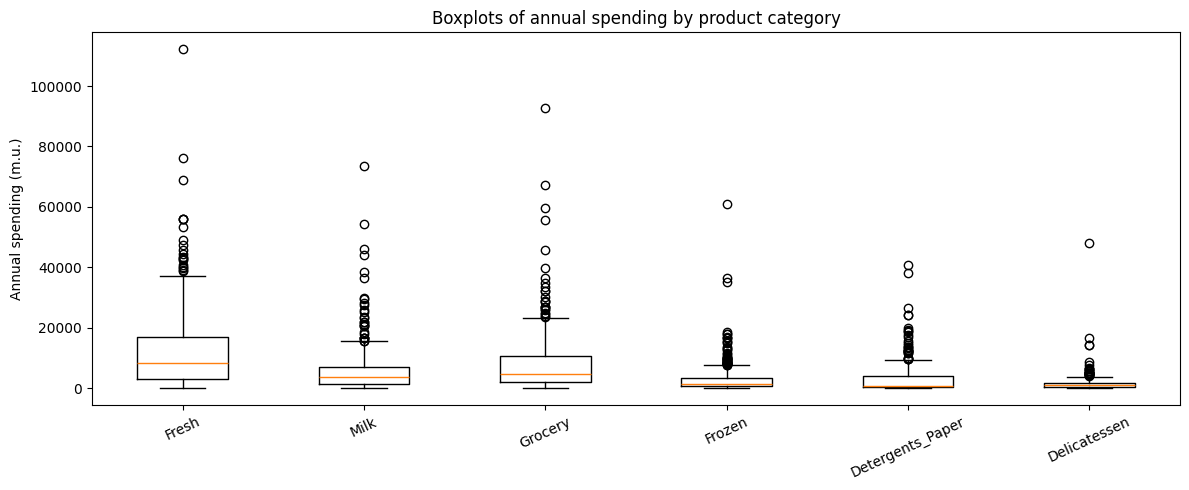

In [6]:
skew_table = pd.DataFrame({
    "skewness": df[spend_cols].skew(),
    "zero_count": (df[spend_cols] == 0).sum(),
    "unique_values": df[spend_cols].nunique()
}).sort_values("skewness", ascending=False)
display(skew_table.round(3))

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), spend_cols):
    ax.hist(df[col], bins=30, edgecolor="black", alpha=0.8)
    ax.set_title(col)
    ax.set_xlabel("Annual spending (m.u.)")
    ax.set_ylabel("Customers")
plt.suptitle("Raw annual spending distributions", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12, 5))
ax.boxplot([df[c] for c in spend_cols], tick_labels=spend_cols, showfliers=True)
ax.set_title("Boxplots of annual spending by product category")
ax.set_ylabel("Annual spending (m.u.)")
ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

The six histograms show strongly right-skewed spending distributions. Most customers are concentrated at lower-to-middle spending levels, while a smaller number have very high annual expenditure. Delicatessen is the most skewed category (skewness 11.152), followed by Frozen (5.908), Milk (4.054), Detergents_Paper (3.632), Grocery (3.587) and Fresh (2.561). This supports the decision to transform the spending variables before calculating distances.  
The boxplots reinforce the histogram findings: all categories contain high-end observations beyond the main body of the data. These points are not automatically errors. In a wholesale setting they may represent genuinely large accounts, so the notebook retained valid observations rather than deleting them solely because they were extreme.  

### 2.2 Initial data-quality assessment

The dataset is checked for missing values, duplicate records, invalid negative spending and non-numeric spending fields. If duplicates exist, they are reported but not automatically deleted: identical customer spending profiles could represent different customers, and no unique customer identifier is supplied to prove that a row is an accidental duplicate.

**Preparation decision:** retain all valid customer records, apply `log1p` to the six spending fields, and standardise the transformed values. Do not remove high-spending observations solely because they are statistically extreme.

In [7]:
quality = {
    "rows": len(df),
    "missing_cells": int(df.isna().sum().sum()),
    "duplicate_rows": int(df.duplicated().sum()),
    "negative_spending_cells": int((df[spend_cols] < 0).sum().sum()),
    "non_numeric_spending_columns": [
        c for c in spend_cols if not pd.api.types.is_numeric_dtype(df[c])
    ]
}
display(pd.Series(quality, name="Observed value").to_frame())

if df[spend_cols].isna().any().any():
    raise ValueError("Missing spending values detected. Review and document imputation before clustering.")
if (df[spend_cols] < 0).any().any():
    raise ValueError("Negative spending values detected. Investigate before log1p transformation.")
if not all(pd.api.types.is_numeric_dtype(df[c]) for c in spend_cols):
    raise TypeError("All spending columns must be numeric.")

,Observed value
rows,440
missing_cells,0
duplicate_rows,0
negative_spending_cells,0
non_numeric_spending_columns,[]


## 3. Data preparation

### 3.1 Transformation and scaling

The spending distributions are inspected before transformation. `log1p(x) = log(1+x)` is used because it accommodates zero spending and compresses the upper tail. StandardScaler then centres each transformed variable and scales it to unit variance.

This two-stage preparation reduces the dominance of very large monetary values and places the six categories on comparable scales. The transformation changes the geometry of the data, so the clusters should be interpreted as similarities in transformed spending profiles, not as raw monetary distances.

`Channel` and `Region` are deliberately excluded from clustering. They are categorical codes, and treating codes such as 1, 2 and 3 as continuous distances would impose an unjustified numerical ordering.

Prepared feature matrix: (440, 6)


,count,mean,std,min,25%,50%,75%,max
Fresh,440.0,0.0,1.001,-5.001,-0.466,0.215,0.684,1.971
Milk,440.0,-0.0,1.001,-3.795,-0.728,0.069,0.703,2.857
Grocery,440.0,-0.0,1.001,-6.355,-0.691,0.023,0.749,2.698
Frozen,440.0,0.0,1.001,-3.159,-0.541,0.022,0.682,2.900
Detergents_Paper,440.0,-0.0,1.001,-3.166,-0.726,-0.050,0.868,2.240
Delicatessen,440.0,-0.0,1.001,-4.089,-0.508,0.157,0.647,3.177


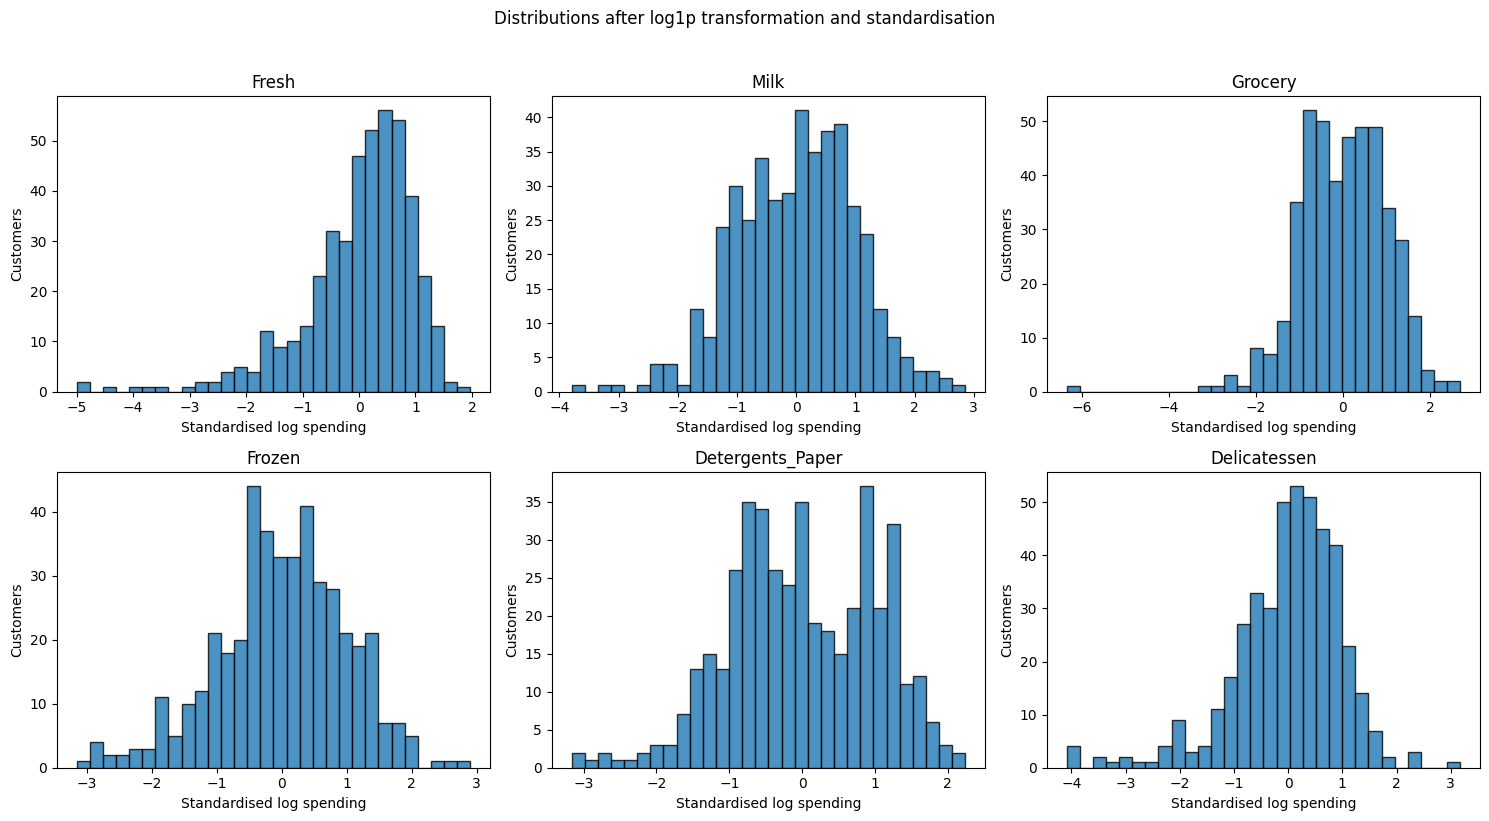

In [8]:
X_raw = df[spend_cols].copy()
X_log = np.log1p(X_raw)
scaler = StandardScaler()
X_scaled_array = scaler.fit_transform(X_log)
X_scaled = pd.DataFrame(X_scaled_array, columns=spend_cols, index=df.index)

print("Prepared feature matrix:", X_scaled.shape)
display(X_scaled.describe().T.round(3))

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), spend_cols):
    ax.hist(X_scaled[col], bins=30, edgecolor="black", alpha=0.8)
    ax.set_title(col)
    ax.set_xlabel("Standardised log spending")
    ax.set_ylabel("Customers")
plt.suptitle("Distributions after log1p transformation and standardisation", y=1.02)
plt.tight_layout()
plt.show()

After applying log1p and standardising each category, the variables are centred near zero and have approximately unit standard deviation. The long right tails are compressed, reducing the dominance of very large values. Standardisation also puts all six categories on a comparable scale so that categories with larger raw monetary amounts do not dominate Euclidean distance simply because of their scale.

## 4. Cluster tendency

Cluster tendency asks whether the observations contain meaningful grouping structure, rather than merely forming a continuous or uniform cloud. A clustering algorithm will always return groups when instructed to do so; that alone is not evidence that natural clusters exist.

The **Hopkins statistic** is used as a diagnostic. It compares nearest-neighbour distances for sampled real observations with distances for artificial points sampled uniformly within the data range. Values near 0.5 are consistent with spatial randomness; values substantially above 0.5 indicate a tendency to cluster. Results depend on sample size, scaling and the sampling region, so the statistic is interpreted as supporting evidence, not proof.

The calculation below is repeated five times to reduce reliance on one random sample.

In [9]:
def hopkins_statistic(X, sample_size=50, random_state=42):
    X = np.asarray(X, dtype=float)
    rng = np.random.default_rng(random_state)
    n, d = X.shape
    m = min(sample_size, max(1, n // 10))
    mins, maxs = X.min(axis=0), X.max(axis=0)

    real_idx = rng.choice(n, size=m, replace=False)
    real_points = X[real_idx]
    artificial = rng.uniform(mins, maxs, size=(m, d))

    nn = NearestNeighbors(n_neighbors=2).fit(X)
    # Distance from each sampled real point to its nearest *other* real point.
    real_dist = nn.kneighbors(real_points, n_neighbors=2)[0][:, 1]
    # Distance from each artificial point to its nearest real observation.
    artificial_dist = nn.kneighbors(artificial, n_neighbors=1)[0][:, 0]

    denom = artificial_dist.sum() + real_dist.sum()
    return artificial_dist.sum() / denom if denom else np.nan

hopkins_values = [hopkins_statistic(X_scaled, random_state=seed) for seed in range(5)]
display(pd.DataFrame({"repeat": range(1, 6), "Hopkins statistic": hopkins_values}))
print(f"Mean Hopkins statistic: {np.mean(hopkins_values):.3f}")
print("Interpretation: values materially above 0.5 support clustering tendency; values near 0.5 indicate weak evidence.")

,repeat,Hopkins statistic
0,1,0.812228
1,2,0.793059
2,3,0.816133
3,4,0.788140
4,5,0.798519


Mean Hopkins statistic: 0.802
Interpretation: values materially above 0.5 support clustering tendency; values near 0.5 indicate weak evidence.


K-Means and Ward agglomerative clustering were evaluated for cluster counts from 2 to 8 using Silhouette, Davies–Bouldin and Calinski–Harabasz indices. The strongest Silhouette score for both methods occurred at k = 2. K-Means at k = 2 achieved Silhouette = 0.290, Davies–Bouldin = 1.352 and Calinski–Harabasz = 189.050. Ward at k = 2 achieved 0.258, 1.600 and 134.624 respectively. Higher Silhouette and Calinski–Harabasz values are preferred; lower Davies–Bouldin is preferred. On these reported metrics, K-Means at k = 2 is the stronger of the two reference solutions.

## 5. Model comparison

Three families are compared, as required by the assignment:

1. **Partitioning – K-Means:** assigns every customer to one of *k* clusters by minimising within-cluster squared Euclidean distances. It is efficient and produces straightforward segment centroids, but requires *k* in advance and is sensitive to initialisation and outliers.
2. **Hierarchical – Agglomerative (Ward):** begins with individual observations and repeatedly merges groups. Ward linkage chooses merges that minimise the increase in within-cluster variance. It provides a hierarchy and does not require random initial centroids, but the final cut level (number of clusters) must still be selected.
3. **Density-based – DBSCAN:** groups observations in dense neighbourhoods and labels sparse observations as noise. It can identify irregularly shaped dense groups and does not require a pre-set number of clusters, but results are sensitive to `eps` and `min_samples`; variable-density customer data can be difficult for DBSCAN.

### 5.1 Selecting the number of clusters for K-Means and hierarchical clustering

Silhouette is higher when observations are close to their own cluster and separated from other clusters. Davies–Bouldin is lower for better-separated, compact clusters. Calinski–Harabasz is higher when between-cluster dispersion is large relative to within-cluster dispersion.

These internal metrics do not establish commercial usefulness. They are used together with cluster sizes, profiles and interpretability.

In [10]:
def internal_scores(X, labels):
    labels = np.asarray(labels)
    unique = np.unique(labels)
    if len(unique) < 2 or len(unique) >= len(labels):
        return {"silhouette": np.nan, "davies_bouldin": np.nan, "calinski_harabasz": np.nan}
    return {
        "silhouette": silhouette_score(X, labels),
        "davies_bouldin": davies_bouldin_score(X, labels),
        "calinski_harabasz": calinski_harabasz_score(X, labels)
    }

candidate_ks = range(2, 9)
partition_rows, hierarchy_rows = [], []
kmeans_models, ward_models = {}, {}

for k in candidate_ks:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    km_labels = km.fit_predict(X_scaled)
    kmeans_models[k] = (km, km_labels)
    partition_rows.append({"algorithm": "K-Means", "k": k, **internal_scores(X_scaled, km_labels)})

    ward = AgglomerativeClustering(n_clusters=k, linkage="ward")
    ward_labels = ward.fit_predict(X_scaled)
    ward_models[k] = (ward, ward_labels)
    hierarchy_rows.append({"algorithm": "Ward agglomerative", "k": k, **internal_scores(X_scaled, ward_labels)})

kmeans_results = pd.DataFrame(partition_rows)
ward_results = pd.DataFrame(hierarchy_rows)
display(kmeans_results.round(3))
display(ward_results.round(3))

,algorithm,k,silhouette,davies_bouldin,calinski_harabasz
0,K-Means,2,0.290,1.352,189.050
1,K-Means,3,0.258,1.348,152.837
2,K-Means,4,0.188,1.541,131.320
3,K-Means,5,0.192,1.484,118.000
4,K-Means,6,0.195,1.414,108.300
5,K-Means,7,0.196,1.392,103.208
6,K-Means,8,0.191,1.385,97.386


,algorithm,k,silhouette,davies_bouldin,calinski_harabasz
0,Ward agglomerative,2,0.258,1.600,134.624
1,Ward agglomerative,3,0.255,1.539,116.799
2,Ward agglomerative,4,0.202,1.521,108.607
3,Ward agglomerative,5,0.203,1.386,100.015
4,Ward agglomerative,6,0.171,1.490,94.857
5,Ward agglomerative,7,0.163,1.498,91.301
6,Ward agglomerative,8,0.148,1.587,86.612


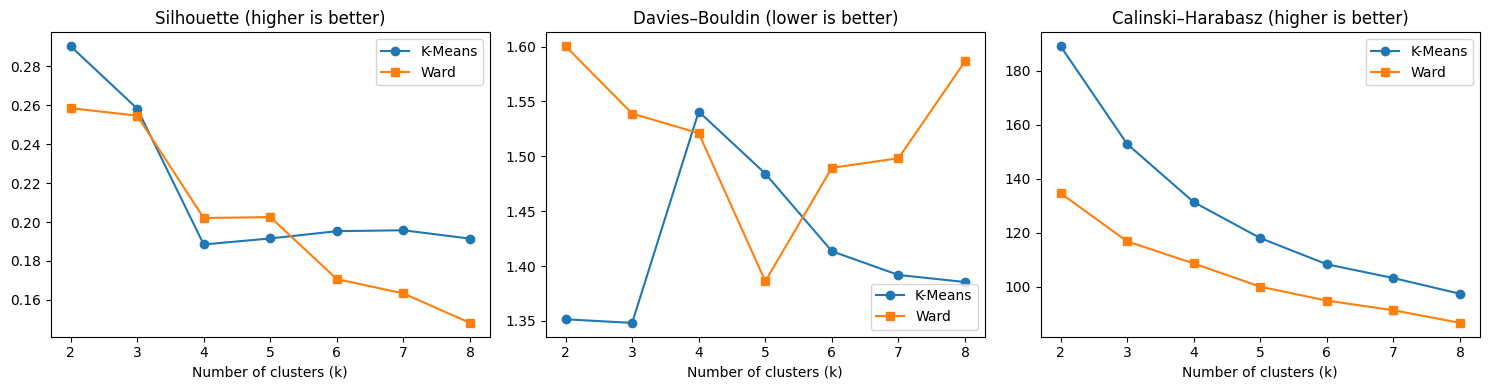

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
metrics = [
    ("silhouette", "Silhouette (higher is better)"),
    ("davies_bouldin", "Davies–Bouldin (lower is better)"),
    ("calinski_harabasz", "Calinski–Harabasz (higher is better)")
]
for ax, (metric, title) in zip(axes, metrics):
    ax.plot(kmeans_results["k"], kmeans_results[metric], marker="o", label="K-Means")
    ax.plot(ward_results["k"], ward_results[metric], marker="s", label="Ward")
    ax.set_xlabel("Number of clusters (k)")
    ax.set_title(title)
    ax.set_xticks(list(candidate_ks))
    ax.legend()
plt.tight_layout()
plt.show()

The three panels compare the two methods as the number of clusters increases. The Silhouette panel is highest at k = 2 for both methods and generally declines as additional clusters are introduced. The Calinski–Harabasz panel also favours k = 2. Davies–Bouldin is lowest for K-Means at k = 2, while Ward’s lowest value occurs at a larger k; taken together, the metrics support k = 2 as the clearest overall choice, especially for K-Means.

### 5.2 Hierarchical structure

The dendrogram gives a visual view of the merge structure. A large vertical jump can suggest a plausible cut, but dendrogram height alone does not determine the best number of clusters. The metric comparison and the practical usefulness of the resulting profiles are considered together.

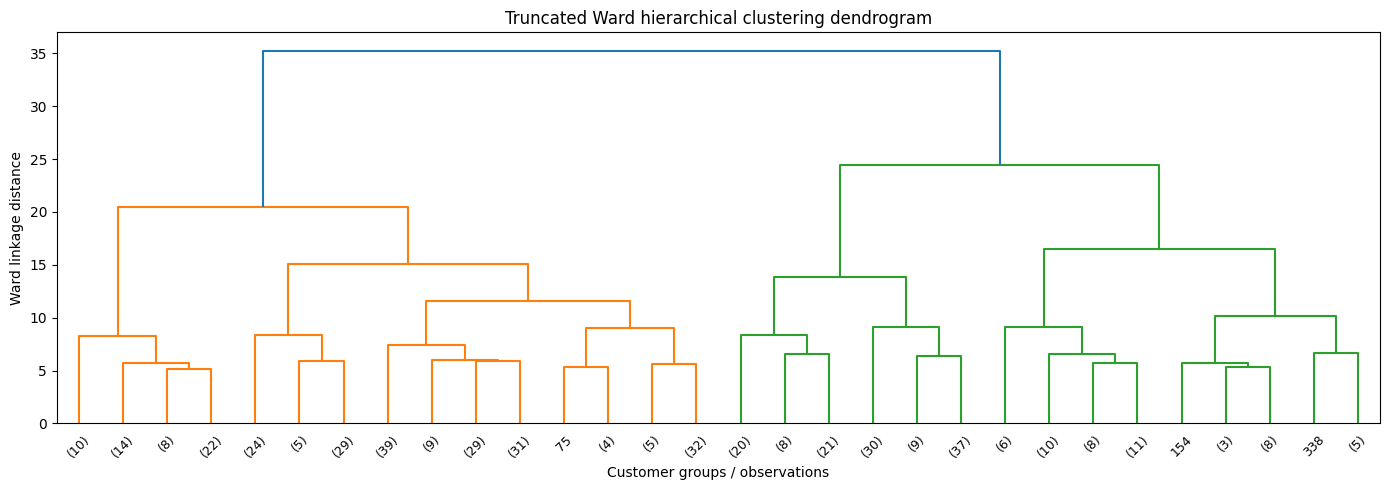

In [12]:
from scipy.cluster.hierarchy import linkage, dendrogram

Z = linkage(X_scaled, method="ward")
fig, ax = plt.subplots(figsize=(14, 5))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=45, leaf_font_size=9, ax=ax)
ax.set_title("Truncated Ward hierarchical clustering dendrogram")
ax.set_xlabel("Customer groups / observations")
ax.set_ylabel("Ward linkage distance")
plt.tight_layout()
plt.show()

### 5.3 DBSCAN parameter sensitivity

DBSCAN requires `eps` (neighbourhood radius) and `min_samples` (minimum local neighbourhood size). A single arbitrary parameter setting would be difficult to defend. The analysis therefore examines several `eps` values derived from the distribution of each observation's *k*-nearest-neighbour distance, for `min_samples` values of 5 and 10.

For each setting, the table reports the number of non-noise clusters, noise proportion, silhouette among assigned observations, and the two additional internal metrics when valid. A high silhouette based on a tiny assigned subset is not automatically preferred; coverage is essential.

In [13]:
dbscan_rows = []
dbscan_models = {}
for min_samples in [5, 10]:
    nn = NearestNeighbors(n_neighbors=min_samples).fit(X_scaled)
    distances, _ = nn.kneighbors(X_scaled)
    kth_dist = np.sort(distances[:, -1])
    for q in [0.50, 0.70, 0.85, 0.90, 0.95, 0.98, 0.99, 0.995]:
        eps = float(np.quantile(kth_dist, q))
        model = DBSCAN(eps=eps, min_samples=min_samples)
        labels = model.fit_predict(X_scaled)
        assigned = labels != -1
        n_clusters = len(set(labels) - {-1})
        noise_prop = float((~assigned).mean())
        if assigned.sum() > 2 and len(set(labels[assigned])) >= 2:
            scores = internal_scores(X_scaled[assigned], labels[assigned])
        else:
            scores = {"silhouette": np.nan, "davies_bouldin": np.nan, "calinski_harabasz": np.nan}
        row = {
            "min_samples": min_samples, "eps_quantile": q, "eps": eps,
            "clusters_excluding_noise": n_clusters,
            "noise_proportion": noise_prop,
            **scores
        }
        dbscan_rows.append(row)
        dbscan_models[(min_samples, q)] = (model, labels)

dbscan_results = pd.DataFrame(dbscan_rows)
display(dbscan_results.round(3))

,min_samples,eps_quantile,eps,clusters_excluding_noise,noise_proportion,silhouette,davies_bouldin,calinski_harabasz
0,5,0.500,0.956,3,0.316,0.249,0.852,27.038
1,5,0.700,1.126,1,0.193,NaN,NaN,NaN
2,5,0.850,1.509,1,0.093,NaN,NaN,NaN
3,5,0.900,1.690,1,0.061,NaN,NaN,NaN
4,5,0.950,2.140,1,0.020,NaN,NaN,NaN
5,5,0.980,2.603,1,0.009,NaN,NaN,NaN
6,5,0.990,3.165,1,0.007,NaN,NaN,NaN
7,5,0.995,4.082,1,0.002,NaN,NaN,NaN
8,10,0.500,1.103,2,0.277,0.261,0.785,19.364
9,10,0.700,1.356,1,0.152,NaN,NaN,NaN


### 5.4 Select and compare representative solutions

For K-Means and Ward, the candidate with the highest silhouette is selected as a transparent internal-metric reference. The resulting cluster sizes and other metrics are also checked; the maximum silhouette is not treated as an automatic business optimum.

For DBSCAN, candidate solutions are considered only when at least two non-noise clusters are found and at least 50% of customers are assigned. Among those candidates, the highest assigned-observation silhouette is used as a reference. If no candidate meets these conditions, DBSCAN is reported as unsuitable under the tested parameter range rather than forcing a misleading solution.

In [14]:
best_k_km = int(kmeans_results.loc[kmeans_results["silhouette"].idxmax(), "k"])
best_k_ward = int(ward_results.loc[ward_results["silhouette"].idxmax(), "k"])

km_model, km_labels = kmeans_models[best_k_km]
ward_model, ward_labels = ward_models[best_k_ward]

eligible_db = dbscan_results[
    (dbscan_results["clusters_excluding_noise"] >= 2) &
    (dbscan_results["noise_proportion"] <= 0.50) &
    (dbscan_results["silhouette"].notna())
]
if len(eligible_db):
    db_choice = eligible_db.sort_values("silhouette", ascending=False).iloc[0]
    db_key = (int(db_choice["min_samples"]), float(db_choice["eps_quantile"]))
    db_model, db_labels = dbscan_models[db_key]
    db_choice_label = f"DBSCAN (min_samples={db_key[0]}, eps quantile={db_key[1]:.2f})"
else:
    db_model, db_labels = None, None
    db_choice_label = "No DBSCAN solution met the minimum coverage and cluster-count criteria."

comparison_rows = [
    {"method": "K-Means", "selected_solution": f"k={best_k_km}",
     "clusters": len(np.unique(km_labels)), "noise_proportion": 0.0,
     **internal_scores(X_scaled, km_labels)},
    {"method": "Ward agglomerative", "selected_solution": f"k={best_k_ward}",
     "clusters": len(np.unique(ward_labels)), "noise_proportion": 0.0,
     **internal_scores(X_scaled, ward_labels)}
]
if db_model is not None:
    assigned = db_labels != -1
    comparison_rows.append({
        "method": "DBSCAN", "selected_solution": db_choice_label,
        "clusters": len(set(db_labels) - {-1}),
        "noise_proportion": float((~assigned).mean()),
        **internal_scores(X_scaled[assigned], db_labels[assigned])
    })
else:
    comparison_rows.append({
        "method": "DBSCAN", "selected_solution": db_choice_label,
        "clusters": 0, "noise_proportion": np.nan,
        "silhouette": np.nan, "davies_bouldin": np.nan, "calinski_harabasz": np.nan
    })

comparison = pd.DataFrame(comparison_rows)
display(comparison.round(3))
print("Selected K-Means k:", best_k_km)
print("Selected Ward k:", best_k_ward)
print("DBSCAN assessment:", db_choice_label)

,method,selected_solution,clusters,noise_proportion,silhouette,davies_bouldin,calinski_harabasz
0,K-Means,k=2,2,0.000,0.290,1.352,189.050
1,Ward agglomerative,k=2,2,0.000,0.258,1.600,134.624
2,DBSCAN,"DBSCAN (min_samples=10, eps quantile=0.50)",2,0.277,0.261,0.785,19.364


Selected K-Means k: 2
Selected Ward k: 2
DBSCAN assessment: DBSCAN (min_samples=10, eps quantile=0.50)


### 5.5 Sensitivity to K-Means initialisation

K-Means can produce different local optima because it starts from initial centroids. The selected number of clusters is therefore refitted across several random seeds. The inertia and silhouette range are reported. Similar scores across seeds provide some reassurance that the selected result is not an artefact of one initialisation; they do not prove full cluster stability.

In [15]:
seed_rows = []
for seed in [0, 7, 21, 42, 99, 123]:
    model = KMeans(n_clusters=best_k_km, random_state=seed, n_init=20)
    labels = model.fit_predict(X_scaled)
    seed_rows.append({
        "random_seed": seed,
        "inertia": model.inertia_,
        "silhouette": silhouette_score(X_scaled, labels)
    })
seed_sensitivity = pd.DataFrame(seed_rows)
display(seed_sensitivity.round(4))
print("Silhouette range:", round(seed_sensitivity.silhouette.min(), 4),
      "to", round(seed_sensitivity.silhouette.max(), 4))

,random_seed,inertia,silhouette
0,0,1844.0641,0.2903
1,7,1844.0641,0.2903
2,21,1844.0641,0.2903
3,42,1844.0641,0.2903
4,99,1844.0641,0.2903
5,123,1844.0641,0.2903


Silhouette range: 0.2903 to 0.2903


## 6. Cluster interpretation and customer profiles

K-Means is used as the primary segmentation solution for the business profile because it assigns every customer to one segment and provides interpretable centroids. This choice is conditional on the diagnostics above: it is not a claim that K-Means is universally superior. Ward clustering provides an independent hierarchical comparison, while DBSCAN's ability (or inability) to identify sufficiently broad dense groups is considered explicitly.

Cluster labels are descriptive names based on each segment's relative spending mix. Names are generated from the observed category profile rather than being treated as pre-existing customer types. The table reports raw monetary means and medians, plus within-segment shares of total spending to support interpretation.

In [16]:
# Primary business segmentation
profile_df = df[spend_cols].copy()
profile_df["Cluster"] = km_labels

cluster_means = profile_df.groupby("Cluster")[spend_cols].mean()
cluster_medians = profile_df.groupby("Cluster")[spend_cols].median()
cluster_sizes = profile_df.groupby("Cluster").size().rename("customers")
cluster_shares = cluster_means.div(cluster_means.sum(axis=1), axis=0) * 100

# Rank category means within each cluster to identify dominant spending categories.
dominant = cluster_means.idxmax(axis=1)
second = cluster_means.apply(lambda r: r.nlargest(2).index[-1], axis=1)

def make_segment_name(cluster_id):
    return f"{dominant.loc[cluster_id]}–{second.loc[cluster_id]} focused"

segment_names = {int(c): make_segment_name(c) for c in cluster_means.index}
print("Descriptive segment names:")
display(pd.DataFrame({
    "cluster": cluster_means.index,
    "customers": cluster_sizes.values,
    "descriptive_name": [segment_names[int(c)] for c in cluster_means.index],
    "largest_mean_spend_category": dominant.values
}))

Descriptive segment names:


,cluster,customers,descriptive_name,largest_mean_spend_category
0,0,252,Fresh–Frozen focused,Fresh
1,1,188,Grocery–Milk focused,Grocery


In [17]:
print("Mean annual spending by cluster (monetary units):")
display(cluster_means.round(1))
print("Median annual spending by cluster (monetary units):")
display(cluster_medians.round(1))
print("Share of each cluster's average category spend (%):")
display(cluster_shares.round(1))
print("Cluster sizes:")
display(cluster_sizes.to_frame())

Mean annual spending by cluster (monetary units):


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
Cluster,,,,,,
0,13973.1,2401.8,2918.7,3705.7,491.9,1038.0
1,9355.9,10346.4,14697.1,2222.5,6084.5,2177.4


Median annual spending by cluster (monetary units):


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
Cluster,,,,,,
0,10347.5,1871.0,2406.0,2225.0,327.5,749.5
1,5406.5,7690.5,11527.0,1061.5,4495.0,1388.5


Share of each cluster's average category spend (%):


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
Cluster,,,,,,
0,57.0,9.8,11.9,15.1,2.0,4.2
1,20.8,23.1,32.7,5.0,13.6,4.9


Cluster sizes:


,customers
Cluster,
0,252
1,188


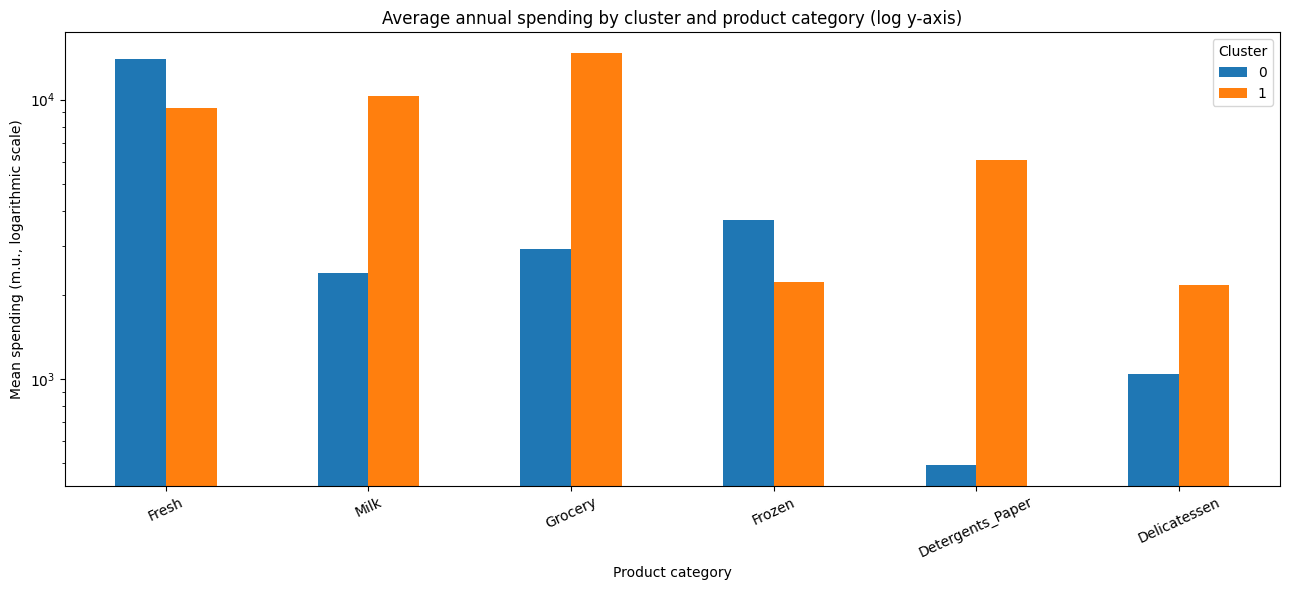

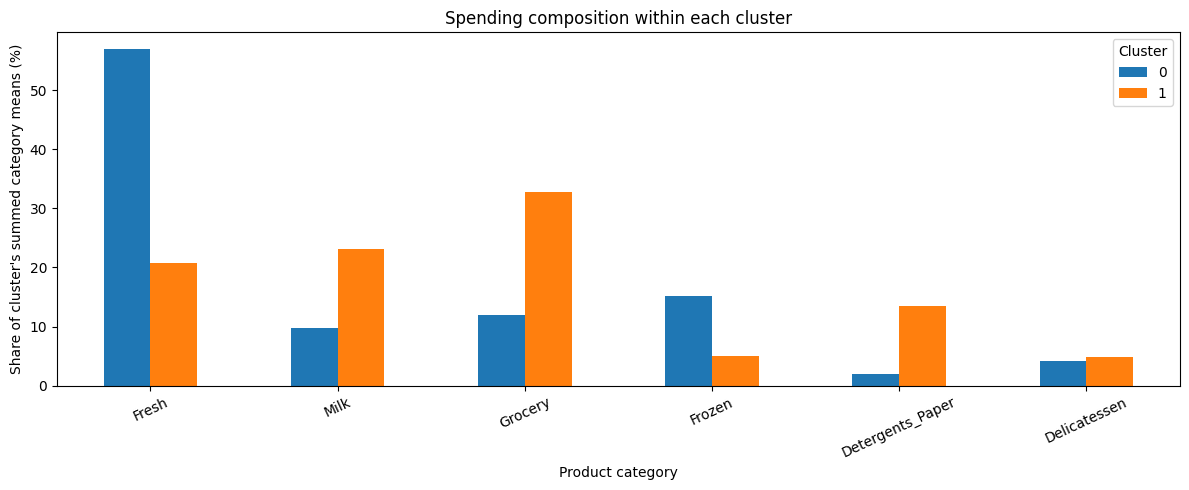

In [18]:
# Visual comparison of mean spending profiles, using a log axis to accommodate scale differences.
fig, ax = plt.subplots(figsize=(13, 6))
cluster_means.T.plot(kind="bar", ax=ax)
ax.set_yscale("log")
ax.set_title("Average annual spending by cluster and product category (log y-axis)")
ax.set_xlabel("Product category")
ax.set_ylabel("Mean spending (m.u., logarithmic scale)")
ax.legend(title="Cluster")
ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12, 5))
cluster_shares.T.plot(kind="bar", ax=ax)
ax.set_title("Spending composition within each cluster")
ax.set_xlabel("Product category")
ax.set_ylabel("Share of cluster's summed category means (%)")
ax.legend(title="Cluster")
ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

### 6.1 Customer descriptors by cluster

`Channel` and `Region` were not used to create clusters. They can nevertheless help the distributor understand whether the spending-based segments are concentrated in particular coded customer groups or regions.

The dataset file supplied for this project does not include a data dictionary defining the numeric codes. Consequently, this notebook reports the codes as supplied and does **not** assign business labels (for example, channel names or geographic names) without documentary support. When the corresponding README/data dictionary is provided, these labels can be added safely.

In [19]:
for col in descriptor_cols:
    print(f"Distribution of {col} within spending clusters (row percentages):")
    tab = pd.crosstab(profile_df["Cluster"], df[col], normalize="index") * 100
    display(tab.round(1))

Distribution of Channel within spending clusters (row percentages):


Channel,1,2
Cluster,,
0,96.8,3.2
1,28.7,71.3


Distribution of Region within spending clusters (row percentages):


Region,1,2,3
Cluster,,,
0,19.0,11.1,69.8
1,15.4,10.1,74.5


## 7. Visualising the segmentation

Principal Component Analysis (PCA) is used only to project the six-dimensional prepared data into two dimensions for visual inspection. PCA is not used to fit the clusters. The plot is therefore a simplified view: separation in two dimensions may understate or distort separation in the original six-dimensional space.

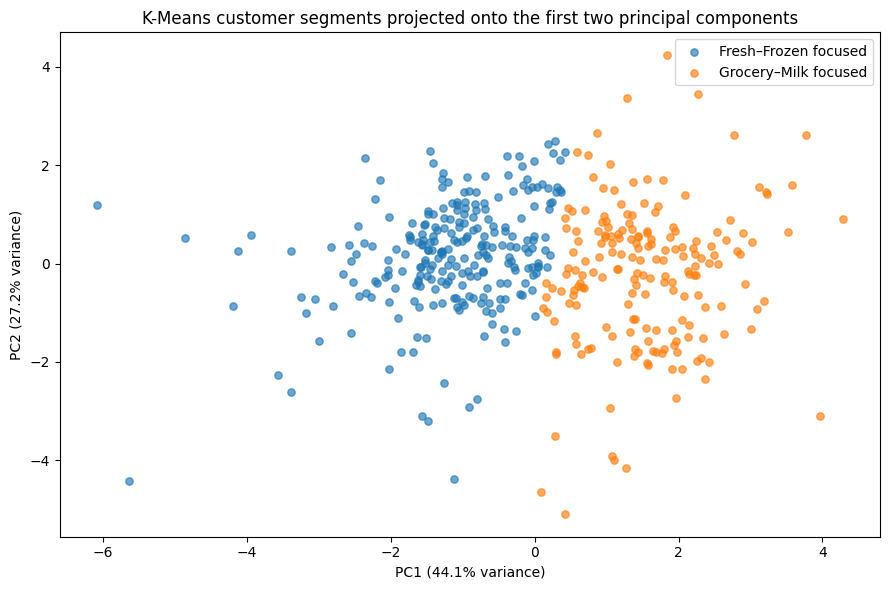

Variance explained by first two PCs: 71.3%


In [20]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0], "PC2": X_pca[:, 1],
    "Cluster": km_labels
})
fig, ax = plt.subplots(figsize=(9, 6))
for c in sorted(pca_df["Cluster"].unique()):
    part = pca_df[pca_df["Cluster"] == c]
    ax.scatter(part["PC1"], part["PC2"], alpha=0.65, s=28, label=segment_names[int(c)])
ax.set_title("K-Means customer segments projected onto the first two principal components")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
ax.legend()
plt.tight_layout()
plt.show()
print(f"Variance explained by first two PCs: {pca.explained_variance_ratio_.sum()*100:.1f}%")

The plot displays the six-dimensional spending data in two dimensions using PCA, with points coloured by their K-Means cluster. The first two principal components explain 71.3% of the variance. The figure offers a useful visual check of how the groups appear in a reduced view, but PCA was used only for visualisation; the clustering itself was performed using all six prepared spending variables. Some overlap in a two-dimensional projection does not invalidate the original six-dimensional clustering.

## 8. Critical discussion of the three approaches

Use the comparison table and diagnostics above to complete the evidence-based assessment:

- **K-Means:** produces complete assignments and clear centroids, making it practical for customer-level action. Its limitations are the need to choose *k*, preference for compact approximately spherical groups, and sensitivity to scaling and initialisation. The log transformation and seed sensitivity analysis partly address these concerns.
- **Ward hierarchical clustering:** provides a nested view of customer similarity and can be interpreted through its dendrogram. It also requires a cut level, and once observations are merged, those merges cannot be undone. Its quality should be judged using the same internal metrics and resulting profiles.
- **DBSCAN:** can mark sparse observations as noise and detect non-spherical dense structures. It does not force every customer into a segment, which may be useful for identifying unusual spending profiles. However, the result depends strongly on `eps` and `min_samples`; a large noise share or too few clusters limits its usefulness for a complete sales segmentation.

**Interpretation rule:** do not declare a universal winner based on one metric. A defensible selection balances separation, compactness, coverage, stability, interpretability and the distributor's need to act on the segments.

## 9. Business recommendations

The recommendations below should be linked to the actual cluster profiles printed above. The distributor should not assume that every customer in a segment behaves identically; cluster membership is a decision-support signal, not a permanent customer identity.

| Observed segment profile | Proportionate service response |
|---|---|
| High Fresh spending | Prioritise reliable replenishment, freshness/quality controls and delivery scheduling; consider volume-based terms only after margin review. |
| High Milk / Grocery spending | Offer coordinated replenishment, category bundles and account-level promotions across complementary lines. |
| High Frozen spending | Emphasise cold-chain reliability, delivery frequency options and stock-availability communication. |
| High Detergents/Paper spending | Use targeted cross-selling, bulk-order offers and predictable replenishment arrangements. |
| High Delicatessen spending | Offer assortment flexibility and monitor product mix and order frequency. |
| Broad high-spend customers | Consider key-account service, demand planning and negotiated service levels, subject to profitability. |
| Low or narrow-category spenders | Use low-cost digital communication, targeted introductory offers and monitor response before investing in intensive account management. |

These are conditional actions: apply a recommendation only where the corresponding cluster's observed profile supports it. Before discounts or special delivery terms are introduced, the distributor should check gross margin, payment behaviour, delivery cost and customer lifetime value, none of which are included in this dataset.

In [21]:
# Generate a concise, data-driven profile summary for use in the final report.
summary_rows = []
for c in cluster_means.index:
    summary_rows.append({
        "cluster": int(c),
        "segment_name": segment_names[int(c)],
        "customers": int(cluster_sizes.loc[c]),
        "customer_share_pct": 100 * cluster_sizes.loc[c] / len(df),
        "largest_mean_spend_category": dominant.loc[c],
        "second_largest_category": second.loc[c],
        "mean_total_spend": float(cluster_means.loc[c].sum())
    })
segment_summary = pd.DataFrame(summary_rows).sort_values("cluster")
display(segment_summary.round(2))

,cluster,segment_name,customers,customer_share_pct,largest_mean_spend_category,second_largest_category,mean_total_spend
0,0,Fresh–Frozen focused,252,57.27,Fresh,Frozen,24529.24
1,1,Grocery–Milk focused,188,42.73,Grocery,Milk,44883.68


## 11. Overall Conclusion

 The analysis found that the customers had a tendency to form groups based on their spending patterns. Among the methods tested, K-Means with two clusters provided the most useful segmentation.

The two groups showed different purchasing patterns: one focused more on Fresh and Frozen products, while the other spent more on Grocery, Milk and Detergents_Paper. These findings can help the business make better decisions about product selection, promotions, stock replenishment, deliveries and customer management.

## 10. Limitations and responsible use

1. **No customer identifiers:** the file has no customer ID, so records cannot be linked to customer histories or checked for repeat-customer duplication.
2. **No data dictionary supplied with this CSV:** numeric `Channel` and `Region` codes are not translated into named categories in this analysis. Add authoritative definitions when the README is available.
3. **Spending only:** annual expenditure does not reveal profitability, order frequency, payment risk, service cost, customer potential or reasons for purchasing.
4. **One observation period:** a single annual profile cannot show whether a customer's behaviour is stable or changing.
5. **Unsupervised validation:** there are no known true segment labels. Internal metrics and visual diagnostics are proxies, not ground truth.
6. **Transformation and distance dependence:** log transformation, scaling and Euclidean distance influence the geometry and therefore the clusters.
7. **Operational caution:** segments should support human decision-making. Customers should not be denied service or assigned punitive terms solely because of a cluster label.

Future work could incorporate transaction-level order frequency, gross margin, delivery cost, payment history and multiple years of customer data, then test whether the segments are stable and commercially predictive.

## References and attribution

- Rousseeuw, P. J. (1987). Silhouettes: A graphical aid to the interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics, 20*, 53–65.
- Davies, D. L., & Bouldin, D. W. (1979). A cluster separation measure. *IEEE Transactions on Pattern Analysis and Machine Intelligence, PAMI-1*(2), 224–227.
- Calinski, T., & Harabasz, J. (1974). A dendrite method for cluster analysis. *Communications in Statistics, 3*(1), 1–27.
- Ester, M., Kriegel, H.-P., Sander, J., & Xu, X. (1996). A density-based algorithm for discovering clusters in large spatial databases with noise. *Proceedings of the Second International Conference on Knowledge Discovery and Data Mining*, 226–231.
- Ward, J. H., Jr. (1963). Hierarchical grouping to optimize an objective function. *Journal of the American Statistical Association, 58*(301), 236–244.

**Software:** Python, pandas, NumPy, Matplotlib, scikit-learn and SciPy. The dependency versions are recorded in `requirements.txt`.